In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity, mean_squared_error
import copy


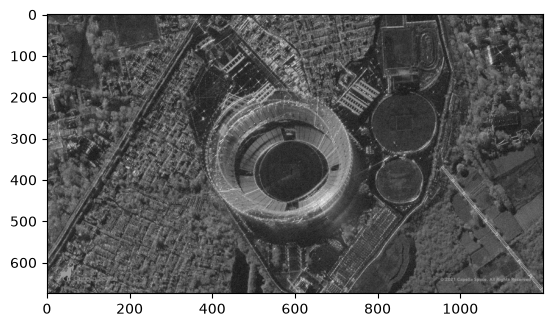

In [3]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 
plt.imshow(image_gray, cmap="gray")

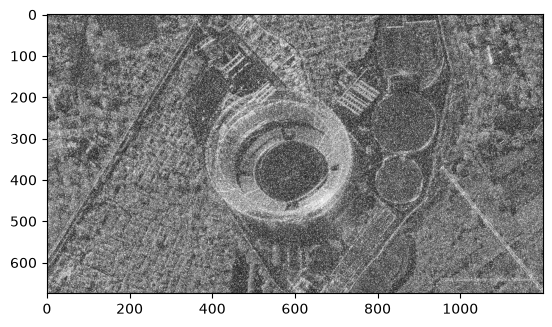

In [4]:
# Шум Гаусса

mean = 0
stddev = 100
noise_gauss = np.zeros(image_gray.shape, np.uint8)
cv2.randn(noise_gauss, mean, stddev)
image_noise_gauss = cv2.add(image_gray,noise_gauss)

plt.imshow(image_noise_gauss, cmap="gray")

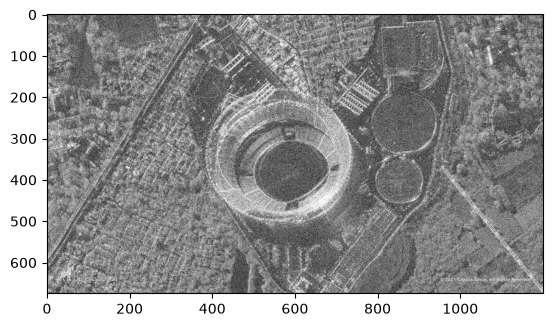

In [5]:
# постоянный шум
image_sp = copy.deepcopy(image_gray)
img_float = image_gray.astype(np.float32)

noise = np.random.uniform(0, 100, img_float.shape)

image_noise = img_float + noise
image_noise = np.clip(image_noise, 0, 255).astype(np.uint8)

plt.imshow(image_noise, cmap='gray')

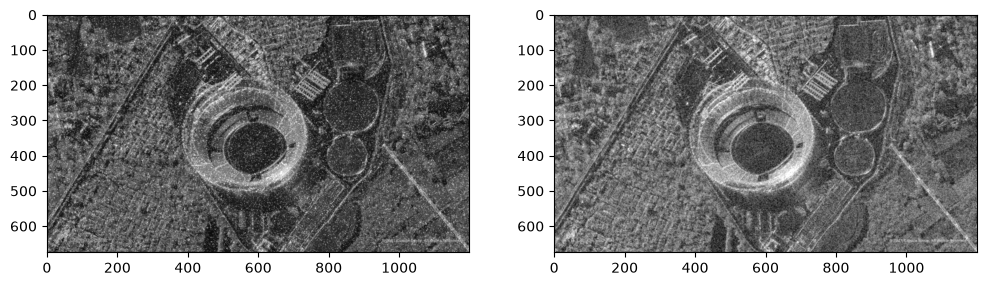

In [6]:
# медианный фильтр
image_gauss_median = cv2.medianBlur(image_noise_gauss, 3)
image_noise_median = cv2.medianBlur(image_noise, 3)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_gauss_median, cmap="gray")
plt.subplot(1, 2, 2)
plt.imshow(image_noise_median, cmap="gray")

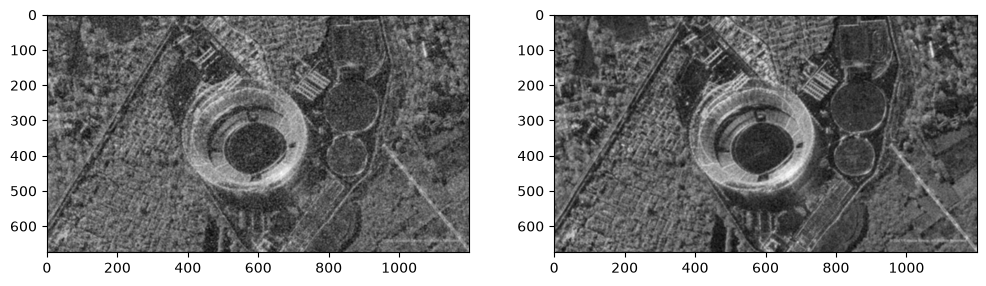

In [7]:
#фильтр Гаусса
image_gauss_gauss = cv2.GaussianBlur(image_noise_gauss,(5,5), 3)
image_noise_gauss = cv2.GaussianBlur(image_noise,(5,5), 3)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_gauss_gauss, cmap="gray")
plt.subplot(1, 2, 2)
plt.imshow(image_noise_gauss, cmap="gray")

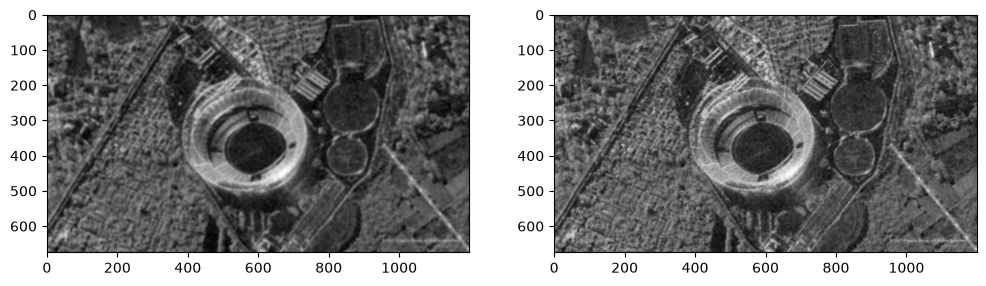

In [8]:
# Билатериальный фильтр
image_gauss_bilat = cv2.bilateralFilter(image_noise_gauss,9,75,75)
noise_image_bilat = cv2.bilateralFilter(image_noise,9,75,75)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_gauss_bilat, cmap="gray")
plt.subplot(1, 2, 2)
plt.imshow(noise_image_bilat, cmap="gray")

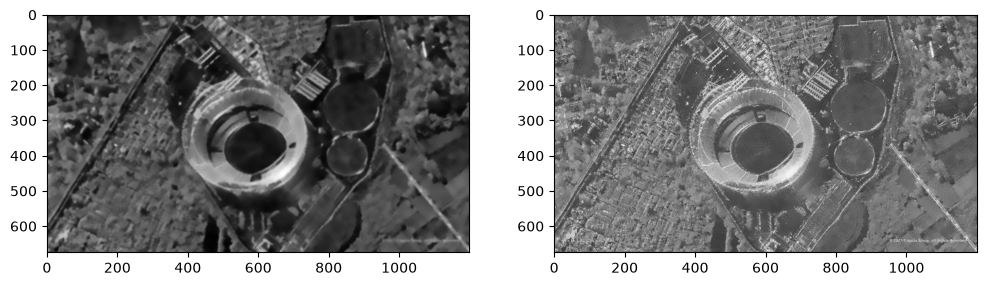

In [9]:
# Фильтр нелокальных средних
image_gauss_nlm = cv2.fastNlMeansDenoising(image_noise_gauss,h = 20)
noise_image_nlm = cv2.fastNlMeansDenoising(image_noise,h = 20)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_gauss_nlm, cmap="gray")
plt.subplot(1, 2, 2)
plt.imshow(noise_image_nlm, cmap="gray")

Median MSE: 2668.26 SSIM: 0.5132


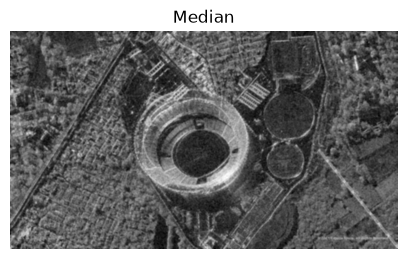

Gaussian MSE: 2696.14 SSIM: 0.476


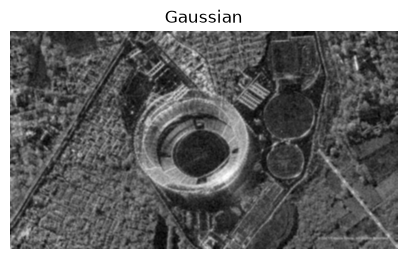

Bilateral MSE: 2735.04 SSIM: 0.414


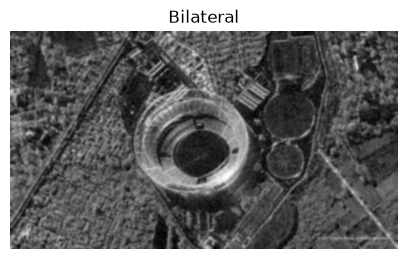

NLM MSE: 2723.08 SSIM: 0.3792


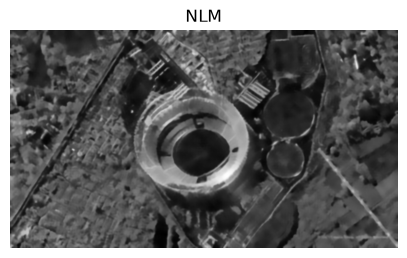

In [ ]:
filters = {
    "Median": cv2.medianBlur(image_noise_gauss, 3),
    "Gaussian": cv2.GaussianBlur(image_noise_gauss, (5, 5), 3),
    "Bilateral": cv2.bilateralFilter(image_noise_gauss, 9, 75, 75),
    "NLM": cv2.fastNlMeansDenoising(image_noise_gauss, h=20)
}

for name, result in filters.items():
    mse = mean_squared_error(image_gray, result)
    ssim, _ = structural_similarity(image_gray, result, full=True)
    print(name, "MSE:", round(mse, 2), "SSIM:", round(ssim, 4))

    plt.figure(figsize=(5, 5))
    plt.title(name)
    plt.imshow(result, cmap="gray")
    plt.axis("off")
    plt.show()

    # Медианный фильтр показал лучший результат